# 08 — PathVQA: Final Test Evaluation of All Models

**Inference only — no training and no pretrained weights.** This notebook reconstructs the architectures directly from the seven supplied training notebooks and loads nine fine-tuned checkpoints from the Kaggle input dataset **`pth_files`**. It evaluates the original, untouched `flaviagiammarino/path-vqa` **test** split (6,719 questions expected). Do not use test results to select hyperparameters or checkpoints.

**Evaluation conventions:** For eight dual-head models, *oracle* routing uses the ground-truth question type to select the yes/no or open head, as in the original training notebooks. Full QTAF-Net and its two dual-head ablations also receive **predicted-type routing** metrics. The single-head ablation uses **direct answer prediction** with 1,002 labels and is not oracle-routed. The image-only model still receives oracle question-type routing despite having no question input. Therefore these metrics are not all equally deployment-realistic.

**Open answer vocabulary limitation:** Predictions are restricted to the 1,000 training answers in the mapping; unseen test answers are never counted as exact matches, but token-F1/BLEU may give partial credit.

**Research note:** ResNet18 was trained from scratch (`weights=None`), unlike the pretrained ResNet18 mentioned in the proposal.


### Kaggle execution guide (submission notes)

**Purpose:** Evaluate saved models on the untouched PathVQA test split. This is **inference only**; it does not train or fine-tune models.

1. Open this notebook in Kaggle, enable a GPU if available, and attach the private `pth_files` dataset containing the saved checkpoints and shared vocabularies. Ensure Kaggle internet access or cached data is available for the PathVQA dataset if required.
2. Run the cells **top to bottom**. The first section checks input paths and loads the saved training mappings; later sections rebuild model classes, load their weights, and generate predictions.
3. The notebook uses Python, PyTorch, torchvision, Hugging Face `datasets`, NumPy, pandas, scikit-learn, NLTK, matplotlib, and standard-library utilities. If Kaggle lacks a dependency, install it before running.
4. Results, per-model prediction CSVs, charts and the final ZIP are written under `/kaggle/working/`. Keep the checkpoint dataset attached when rerunning.

**Reproducibility:** Do not refit vocabulary on the test set. Checkpoint weights are loaded with `strict=True`; a missing or mismatched checkpoint should cause an error rather than a silent substitution. The existing saved outputs are retained and have **not** been freshly reproduced as part of this documentation edit.

## 1. Locate all checkpoints and verify the shared vocabularies

In [1]:
# Prepare the Kaggle environment and import evaluation dependencies.
# Kaggle: attach your private dataset named pth_files via Add Input first.
# If packages are missing, uncomment:
# %pip -q install datasets nltk scikit-learn torchvision
import os, re, glob, json, gc, math, csv, hashlib, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from torchvision.models import resnet18
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import matplotlib.pyplot as plt

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 32
NUM_WORKERS = 2
OUT = Path('/kaggle/working/pathvqa_final_evaluation')
OUT.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE)


Device: cuda


In [3]:
# Confirm the checkpoint dataset is attached before loading any models.
INPUT_ROOT = Path('/kaggle/input/datasets/dollarpaisa/pth-files')
if not INPUT_ROOT.exists():
    raise FileNotFoundError(f'Attach the Kaggle dataset pth_files. Missing {INPUT_ROOT}')

EXPECTED = {
    'Image-Only CNN': 'best_image_only_cnn_finetuned.pth',
    'Question-Only BiLSTM': 'best_question_only_bilstm_finetuned.pth',
    'CNN + BiLSTM': 'best_late_fusion_finetuned.pth',
    'SAN': 'best_san_finetuned.pth',
    'Full QTAF-Net': 'best_qtaf_net_finetuned.pth',
    'QTAF without attention': 'qtaf_ablation_no_attention_finetuned_best.pth',
    'QTAF without type fusion': 'qtaf_ablation_no_type_fusion_finetuned_best.pth',
    'QTAF single head': 'qtaf_ablation_single_head_finetuned_best.pth',
    'ResNet18 + BiLSTM': 'best_resnet18_bilstm_finetuned.pth',
}

def locate(filename):
    hits = sorted(INPUT_ROOT.rglob(filename))
    if len(hits) != 1:
        raise FileNotFoundError(f'Expected exactly one {filename} under {INPUT_ROOT}, found {len(hits)}: {hits}')
    return hits[0]

PATHS = {name: locate(filename) for name, filename in EXPECTED.items()}
VOCAB_PATH = locate('late_fusion_latest.pth')
for name, path in PATHS.items():
    print(f'{name:28s} {path.name} ({path.stat().st_size/1024**2:.1f} MB)')
print('Vocabulary:', VOCAB_PATH)


Image-Only CNN               best_image_only_cnn_finetuned.pth (3.0 MB)
Question-Only BiLSTM         best_question_only_bilstm_finetuned.pth (4.2 MB)
CNN + BiLSTM                 best_late_fusion_finetuned.pth (6.2 MB)
SAN                          best_san_finetuned.pth (6.9 MB)
Full QTAF-Net                best_qtaf_net_finetuned.pth (7.3 MB)
QTAF without attention       qtaf_ablation_no_attention_finetuned_best.pth (6.8 MB)
QTAF without type fusion     qtaf_ablation_no_type_fusion_finetuned_best.pth (6.8 MB)
QTAF single head             qtaf_ablation_single_head_finetuned_best.pth (7.3 MB)
ResNet18 + BiLSTM            best_resnet18_bilstm_finetuned.pth (47.4 MB)
Vocabulary: /kaggle/input/datasets/dollarpaisa/pth-files/PTH FILES/cnn bilstm/late_fusion_latest.pth


In [4]:
# Restore the shared training vocabulary and answer mappings.
# Load only the shared mapping checkpoint with CPU placement. It was created by your own training notebook.
# weights_only=False is necessary for some PyTorch checkpoint formats; use only your trusted files.
shared = torch.load(VOCAB_PATH, map_location='cpu', weights_only=False)
assert isinstance(shared, dict), 'Expected a dictionary checkpoint'
assert 'word2idx' in shared and 'open_answer2idx' in shared, 'Vocabulary keys missing'
word2idx = shared['word2idx']
open_answer2idx = shared['open_answer2idx']
assert isinstance(word2idx, dict) and isinstance(open_answer2idx, dict)
assert len(open_answer2idx) == 1000, 'This evaluation expects the 1,000-answer model'
assert set(open_answer2idx.values()) == set(range(1000)), 'Open-answer mapping is not 0..999'
assert word2idx.get('<PAD>') == 0 and word2idx.get('<UNK>') == 1
idx2open = {i: answer for answer, i in open_answer2idx.items()}
print('Question vocabulary:', len(word2idx), 'Open answer vocabulary:', len(open_answer2idx))
del shared


Question vocabulary: 3972 Open answer vocabulary: 1000


## 2. Reproduce test preprocessing from the training notebooks

In [5]:
# Apply the same question and image preprocessing used during training.
MAX_QUESTION_LENGTH = 32
IMAGE_SIZE = 224

def encode_question(text):
    tokens = re.findall(r"\w+|[^\w\s]", str(text).lower().strip())
    ids = [word2idx.get(token, word2idx['<UNK>']) for token in tokens[:MAX_QUESTION_LENGTH]]
    return ids + [0] * (MAX_QUESTION_LENGTH - len(ids))

def preprocess_image(image):
    image = image.convert('RGB')
    image = ImageOps.contain(image, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.BILINEAR)
    background = Image.new('RGB', (IMAGE_SIZE, IMAGE_SIZE), (255, 255, 255))
    background.paste(image, ((IMAGE_SIZE - image.width)//2, (IMAGE_SIZE - image.height)//2))
    arr = np.asarray(background, dtype=np.float32)/255.0
    return torch.from_numpy(arr).permute(2,0,1)

def normalize_answer(a):
    return str(a).lower().strip()

def encode_answer(a):
    a = normalize_answer(a)
    if a == 'no': return 0, 0
    if a == 'yes': return 0, 1
    return 1, open_answer2idx.get(a, -1)

test_split = load_dataset('flaviagiammarino/path-vqa', split='test')
print('Test examples:', len(test_split))
assert len(test_split) == 6719, 'Unexpected test split size; check dataset version'

class FinalPathVQADataset(Dataset):
    def __init__(self, split): self.split = split
    def __len__(self): return len(self.split)
    def __getitem__(self, idx):
        ex = self.split[idx]
        typ, label = encode_answer(ex['answer'])
        return {'image': preprocess_image(ex['image']),
                'question': torch.tensor(encode_question(ex['question']),dtype=torch.long),
                'type': torch.tensor(typ,dtype=torch.long),
                'label': torch.tensor(label,dtype=torch.long),
                'answer': normalize_answer(ex['answer']),
                'question_text': str(ex['question']),
                'index': idx}

test_loader = DataLoader(FinalPathVQADataset(test_split), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=='cuda'))
print('Batches:',len(test_loader))


README.md:   0%|          | 0.00/4.29k [00:00<?, ?B/s]

data/train-00000-of-00007-f2d0e9ef9f022d(…): reconstructing file:   0%|          |  0.00B / 42.8MB            

data/train-00000-of-00007-f2d0e9ef9f022d(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-47d8e0220bf6c9(…): reconstructing file:   0%|          |  0.00B / 81.0MB            

data/train-00001-of-00007-47d8e0220bf6c9(…): downloading bytes:           |  0.00B            

data/train-00002-of-00007-7fb5037c4c5da7(…): reconstructing file:   0%|          |  0.00B /  104MB            

... (21 outputs left out)

Generating train split:   0%|          | 0/19654 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/6259 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6719 [00:00<?, ? examples/s]

Test examples: 6719
Batches: 210


## 3. Exact model architectures (extracted from your seven uploaded notebooks)

The following definitions are **not approximations**. They are extracted from the model class definitions in the corresponding training notebooks. Separate namespaces avoid name collisions between different `QuestionEncoder` and `SpatialImageEncoder` classes.

### CNN + BiLSTM Late Fusion

In [6]:
# Reconstruct the CNN + BiLSTM late-fusion baseline from saved definitions.
# Source copied from the original uploaded training notebook, class definitions only.
MODEL_SOURCE_LATE = 'class ImageEncoder(nn.Module):\n    def __init__(self, feature_dim=256):\n        super().__init__()\n\n        self.cnn = nn.Sequential(\n            nn.Conv2d(3, 32, kernel_size=3, padding=1),\n            nn.BatchNorm2d(32),\n            nn.ReLU(),\n            nn.MaxPool2d(2),\n\n            nn.Conv2d(32, 64, kernel_size=3, padding=1),\n            nn.BatchNorm2d(64),\n            nn.ReLU(),\n            nn.MaxPool2d(2),\n\n            nn.Conv2d(64, 128, kernel_size=3, padding=1),\n            nn.BatchNorm2d(128),\n            nn.ReLU(),\n            nn.MaxPool2d(2),\n\n            nn.Conv2d(128, 256, kernel_size=3, padding=1),\n            nn.BatchNorm2d(256),\n            nn.ReLU(),\n            nn.AdaptiveAvgPool2d((1, 1))\n        )\n\n        self.fc = nn.Linear(256, feature_dim)\n\n    def forward(self, images):\n        features = self.cnn(images)\n        features = features.flatten(1)\n        return self.fc(features)\n\nclass QuestionEncoder(nn.Module):\n    def __init__(\n        self,\n        vocab_size,\n        embedding_dim=128,\n        hidden_dim=128\n    ):\n        super().__init__()\n\n        self.embedding = nn.Embedding(\n            vocab_size,\n            embedding_dim,\n            padding_idx=0\n        )\n\n        self.lstm = nn.LSTM(\n            input_size=embedding_dim,\n            hidden_size=hidden_dim,\n            batch_first=True,\n            bidirectional=True\n        )\n\n    def forward(self, questions):\n        embedded = self.embedding(questions)\n\n        lengths = (questions != 0).sum(dim=1).clamp(min=1)\n\n        packed = nn.utils.rnn.pack_padded_sequence(\n            embedded,\n            lengths.cpu(),\n            batch_first=True,\n            enforce_sorted=False\n        )\n\n        _, (hidden, _) = self.lstm(packed)\n\n        # Concatenate forward and backward final states\n        question_features = torch.cat(\n            [hidden[-2], hidden[-1]], dim=1\n        )\n\n        return question_features\n\nclass LateFusionVQA(nn.Module):\n    def __init__(\n        self,\n        vocab_size,\n        num_open_answers=1000\n    ):\n        super().__init__()\n\n        self.image_encoder = ImageEncoder(\n            feature_dim=256\n        )\n\n        self.question_encoder = QuestionEncoder(\n            vocab_size=vocab_size\n        )\n\n        self.fusion = nn.Sequential(\n            nn.Linear(512, 256),\n            nn.ReLU(),\n            nn.Dropout(0.3)\n        )\n\n        self.yes_no_head = nn.Linear(256, 2)\n\n        self.open_head = nn.Linear(\n            256, num_open_answers\n        )\n\n    def forward(self, images, questions):\n        image_features = self.image_encoder(images)\n        question_features = self.question_encoder(questions)\n\n        combined = torch.cat(\n            [image_features, question_features],\n            dim=1\n        )\n\n        fused = self.fusion(combined)\n\n        yes_no_logits = self.yes_no_head(fused)\n        open_logits = self.open_head(fused)\n\n        return yes_no_logits, open_logits'
MODEL_NS_LATE = {'torch':torch,'nn':nn,'resnet18':resnet18}
exec(MODEL_SOURCE_LATE, MODEL_NS_LATE)
print('Loaded architecture classes: ImageEncoder, QuestionEncoder, LateFusionVQA')

Loaded architecture classes: ImageEncoder, QuestionEncoder, LateFusionVQA


### Question-Only BiLSTM

In [7]:
# Reconstruct the text-only BiLSTM baseline.
# Source copied from the original uploaded training notebook, class definitions only.
MODEL_SOURCE_QUESTION = 'class QuestionEncoder(nn.Module):\n    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128):\n        super().__init__()\n        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)\n        self.lstm = nn.LSTM(\n            input_size=embedding_dim, hidden_size=hidden_dim,\n            batch_first=True, bidirectional=True\n        )\n\n    def forward(self, questions):\n        embedded = self.embedding(questions)\n        lengths = (questions != 0).sum(dim=1).clamp(min=1)\n        packed = nn.utils.rnn.pack_padded_sequence(\n            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False\n        )\n        _, (hidden, _) = self.lstm(packed)\n        return torch.cat([hidden[-2], hidden[-1]], dim=1)\n\nclass QuestionOnlyBiLSTM(nn.Module):\n    def __init__(self, vocab_size, num_open_answers=1000):\n        super().__init__()\n        self.question_encoder = QuestionEncoder(vocab_size)\n        self.fusion = nn.Sequential(\n            nn.Linear(256, 256),\n            nn.ReLU(),\n            nn.Dropout(0.3)\n        )\n        self.yes_no_head = nn.Linear(256, 2)\n        self.open_head = nn.Linear(256, num_open_answers)\n\n    def forward(self, questions):\n        features = self.question_encoder(questions)\n        shared = self.fusion(features)\n        return self.yes_no_head(shared), self.open_head(shared)'
MODEL_NS_QUESTION = {'torch':torch,'nn':nn,'resnet18':resnet18}
exec(MODEL_SOURCE_QUESTION, MODEL_NS_QUESTION)
print('Loaded architecture classes: QuestionEncoder, QuestionOnlyBiLSTM')

Loaded architecture classes: QuestionEncoder, QuestionOnlyBiLSTM


### Image-Only CNN

In [8]:
# Reconstruct the image-only CNN baseline.
# Source copied from the original uploaded training notebook, class definitions only.
MODEL_SOURCE_IMAGE = 'class ImageEncoder(nn.Module):\n    def __init__(self, feature_dim=256):\n        super().__init__()\n        self.cnn = nn.Sequential(\n            nn.Conv2d(3, 32, kernel_size=3, padding=1),\n            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),\n            nn.Conv2d(32, 64, kernel_size=3, padding=1),\n            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),\n            nn.Conv2d(64, 128, kernel_size=3, padding=1),\n            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),\n            nn.Conv2d(128, 256, kernel_size=3, padding=1),\n            nn.BatchNorm2d(256), nn.ReLU(),\n            nn.AdaptiveAvgPool2d((1, 1))\n        )\n        self.fc = nn.Linear(256, feature_dim)\n\n    def forward(self, images):\n        features = self.cnn(images).flatten(1)\n        return self.fc(features)\n\nclass ImageOnlyCNN(nn.Module):\n    def __init__(self, num_open_answers=1000):\n        super().__init__()\n        self.image_encoder = ImageEncoder(feature_dim=256)\n        self.fusion = nn.Sequential(\n            nn.Linear(256, 256),\n            nn.ReLU(),\n            nn.Dropout(0.3)\n        )\n        self.yes_no_head = nn.Linear(256, 2)\n        self.open_head = nn.Linear(256, num_open_answers)\n\n    def forward(self, images):\n        features = self.image_encoder(images)\n        shared = self.fusion(features)\n        return self.yes_no_head(shared), self.open_head(shared)'
MODEL_NS_IMAGE = {'torch':torch,'nn':nn,'resnet18':resnet18}
exec(MODEL_SOURCE_IMAGE, MODEL_NS_IMAGE)
print('Loaded architecture classes: ImageEncoder, ImageOnlyCNN')

Loaded architecture classes: ImageEncoder, ImageOnlyCNN


### Stacked Attention Network

In [9]:
# Reconstruct the stacked-attention model with spatial visual features.
# Source copied from the original uploaded training notebook, class definitions only.
MODEL_SOURCE_SAN = 'class SpatialImageEncoder(nn.Module):\n    def __init__(self, feature_dim=256):\n        super().__init__()\n        self.cnn = nn.Sequential(\n            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),\n            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),\n            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),\n            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),\n        )\n        self.project = nn.Conv2d(256, feature_dim, kernel_size=1)\n\n    def forward(self, images):\n        features = self.project(self.cnn(images))   # [B, 256, 28, 28]\n        return features.flatten(2).transpose(1, 2)\n\nclass QuestionEncoder(nn.Module):\n    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128):\n        super().__init__()\n        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)\n        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)\n    def forward(self, questions):\n        embeddings = self.embedding(questions)\n        lengths = (questions != 0).sum(dim=1).clamp(min=1)\n        packed = nn.utils.rnn.pack_padded_sequence(\n            embeddings, lengths.cpu(), batch_first=True, enforce_sorted=False\n        )\n        _, (hidden, _) = self.lstm(packed)\n        return torch.cat([hidden[-2], hidden[-1]], dim=1)\n\nclass AttentionHop(nn.Module):\n    def __init__(self, feature_dim=256, attention_dim=256):\n        super().__init__()\n        self.visual = nn.Linear(feature_dim, attention_dim)\n        self.query = nn.Linear(feature_dim, attention_dim)\n        self.score = nn.Linear(attention_dim, 1)\n    def forward(self, spatial_features, query):\n        hidden = torch.tanh(self.visual(spatial_features) + self.query(query).unsqueeze(1))\n        weights = torch.softmax(self.score(hidden).squeeze(-1), dim=1)\n        attended = torch.sum(spatial_features * weights.unsqueeze(-1), dim=1)\n        return query + attended, weights\n\nclass StackedAttentionNetwork(nn.Module):\n    def __init__(self, vocab_size, num_open_answers=1000, num_hops=2):\n        super().__init__()\n        self.image_encoder = SpatialImageEncoder()\n        self.question_encoder = QuestionEncoder(vocab_size)\n        self.hops = nn.ModuleList([AttentionHop() for _ in range(num_hops)])\n        self.classifier = nn.Sequential(nn.Linear(256, 256), nn.ReLU(), nn.Dropout(0.3))\n        self.yes_no_head = nn.Linear(256, 2)\n        self.open_head = nn.Linear(256, num_open_answers)\n\n    def forward(self, images, questions, return_attention=False):\n        visual = self.image_encoder(images)\n        query = self.question_encoder(questions)\n        maps = []\n        for hop in self.hops:\n            query, weights = hop(visual, query)\n            if return_attention: maps.append(weights)\n        features = self.classifier(query)\n        outputs = (self.yes_no_head(features), self.open_head(features))\n        return (*outputs, maps) if return_attention else outputs'
MODEL_NS_SAN = {'torch':torch,'nn':nn,'resnet18':resnet18}
exec(MODEL_SOURCE_SAN, MODEL_NS_SAN)
print('Loaded architecture classes: SpatialImageEncoder, QuestionEncoder, AttentionHop, StackedAttentionNetwork')

Loaded architecture classes: SpatialImageEncoder, QuestionEncoder, AttentionHop, StackedAttentionNetwork


### Full QTAF-Net

In [10]:
# Reconstruct the complete question-type-aware fusion network.
# Source copied from the original uploaded training notebook, class definitions only.
MODEL_SOURCE_QTAF = 'class SpatialImageEncoder(nn.Module):\n    def __init__(self, dim=256):\n        super().__init__()\n        self.cnn = nn.Sequential(\n            nn.Conv2d(3,32,3,padding=1),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(2),\n            nn.Conv2d(32,64,3,padding=1),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(2),\n            nn.Conv2d(64,128,3,padding=1),nn.BatchNorm2d(128),nn.ReLU(),nn.MaxPool2d(2),\n            nn.Conv2d(128,256,3,padding=1),nn.BatchNorm2d(256),nn.ReLU())\n        self.project = nn.Conv2d(256,dim,1)\n    def forward(self,x):\n        return self.project(self.cnn(x)).flatten(2).transpose(1,2)\n\nclass QuestionEncoder(nn.Module):\n    def __init__(self,vocab_size):\n        super().__init__()\n        self.embedding=nn.Embedding(vocab_size,128,padding_idx=0)\n        self.lstm=nn.LSTM(128,128,batch_first=True,bidirectional=True)\n    def forward(self,ids):\n        lengths=(ids!=0).sum(1).clamp(min=1)\n        packed=nn.utils.rnn.pack_padded_sequence(self.embedding(ids),lengths.cpu(),batch_first=True,enforce_sorted=False)\n        _,(h,_)=self.lstm(packed)\n        return torch.cat([h[-2],h[-1]],dim=1)\n\nclass QTAFNet(nn.Module):\n    def __init__(self,vocab_size,num_open_answers=1000):\n        super().__init__()\n        self.image_encoder=SpatialImageEncoder()\n        self.question_encoder=QuestionEncoder(vocab_size)\n        self.att_visual=nn.Linear(256,256)\n        self.att_question=nn.Linear(256,256)\n        self.att_score=nn.Linear(256,1)\n        self.type_head=nn.Sequential(nn.Linear(256,128),nn.ReLU(),nn.Dropout(0.2),nn.Linear(128,2))\n        self.closed_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))\n        self.open_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))\n        self.yes_no_head=nn.Linear(256,2)\n        self.open_head=nn.Linear(256,num_open_answers)\n    def forward(self,images,questions,return_attention=False):\n        spatial=self.image_encoder(images)\n        question=self.question_encoder(questions)\n        energy=torch.tanh(self.att_visual(spatial)+self.att_question(question).unsqueeze(1))\n        attention=torch.softmax(self.att_score(energy).squeeze(-1),dim=1)\n        visual=(spatial*attention.unsqueeze(-1)).sum(1)\n        type_logits=self.type_head(question)\n        type_probs=torch.softmax(type_logits,dim=1)\n        joint=torch.cat([visual,question],dim=1)\n        closed_feature=self.closed_fusion(joint)\n        open_feature=self.open_fusion(joint)\n        fused=type_probs[:,0:1]*closed_feature+type_probs[:,1:2]*open_feature\n        yn=self.yes_no_head(fused)\n        op=self.open_head(fused)\n        return (yn,op,type_logits,attention) if return_attention else (yn,op,type_logits)'
MODEL_NS_QTAF = {'torch':torch,'nn':nn,'resnet18':resnet18}
exec(MODEL_SOURCE_QTAF, MODEL_NS_QTAF)
print('Loaded architecture classes: SpatialImageEncoder, QuestionEncoder, QTAFNet')

Loaded architecture classes: SpatialImageEncoder, QuestionEncoder, QTAFNet


### QTAF-Net ablation variants

In [11]:
# Reconstruct the three QTAF ablation configurations.
# Source copied from the original uploaded training notebook, class definitions only.
MODEL_SOURCE_ABLATION = "class SpatialImageEncoder(nn.Module):\n    def __init__(self, dim=256):\n        super().__init__()\n        self.cnn = nn.Sequential(\n            nn.Conv2d(3,32,3,padding=1),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(2),\n            nn.Conv2d(32,64,3,padding=1),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(2),\n            nn.Conv2d(64,128,3,padding=1),nn.BatchNorm2d(128),nn.ReLU(),nn.MaxPool2d(2),\n            nn.Conv2d(128,256,3,padding=1),nn.BatchNorm2d(256),nn.ReLU())\n        self.project = nn.Conv2d(256,dim,1)\n    def forward(self,x):\n        return self.project(self.cnn(x)).flatten(2).transpose(1,2)\n\nclass QuestionEncoder(nn.Module):\n    def __init__(self,vocab_size):\n        super().__init__()\n        self.embedding=nn.Embedding(vocab_size,128,padding_idx=0)\n        self.lstm=nn.LSTM(128,128,batch_first=True,bidirectional=True)\n    def forward(self,ids):\n        lengths=(ids!=0).sum(1).clamp(min=1)\n        packed=nn.utils.rnn.pack_padded_sequence(self.embedding(ids),lengths.cpu(),batch_first=True,enforce_sorted=False)\n        _,(h,_)=self.lstm(packed)\n        return torch.cat([h[-2],h[-1]],dim=1)\n\nclass AblatedQTAFNet(nn.Module):\n    def __init__(self,vocab_size,num_open_answers=1000,variant='no_attention'):\n        super().__init__()\n        assert variant in ('no_attention','no_type_fusion','single_head')\n        self.variant=variant\n        self.image_encoder=SpatialImageEncoder()\n        self.question_encoder=QuestionEncoder(vocab_size)\n        if variant!='no_attention':\n            self.att_visual=nn.Linear(256,256)\n            self.att_question=nn.Linear(256,256)\n            self.att_score=nn.Linear(256,1)\n        self.type_head=nn.Sequential(nn.Linear(256,128),nn.ReLU(),nn.Dropout(0.2),nn.Linear(128,2))\n        if variant=='no_type_fusion':\n            self.shared_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))\n        else:\n            self.closed_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))\n            self.open_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))\n        if variant=='single_head':\n            self.answer_head=nn.Linear(256,2+num_open_answers)\n        else:\n            self.yes_no_head=nn.Linear(256,2)\n            self.open_head=nn.Linear(256,num_open_answers)\n\n    def forward(self,images,questions):\n        spatial=self.image_encoder(images)\n        question=self.question_encoder(questions)\n        if self.variant=='no_attention':\n            visual=spatial.mean(1)\n        else:\n            energy=torch.tanh(self.att_visual(spatial)+self.att_question(question).unsqueeze(1))\n            attention=torch.softmax(self.att_score(energy).squeeze(-1),dim=1)\n            visual=(spatial*attention.unsqueeze(-1)).sum(1)\n        type_logits=self.type_head(question)\n        joint=torch.cat([visual,question],dim=1)\n        if self.variant=='no_type_fusion':\n            fused=self.shared_fusion(joint)\n        else:\n            type_probs=torch.softmax(type_logits,dim=1)\n            closed_feature=self.closed_fusion(joint)\n            open_feature=self.open_fusion(joint)\n            fused=type_probs[:,0:1]*closed_feature+type_probs[:,1:2]*open_feature\n        if self.variant=='single_head':\n            return self.answer_head(fused),type_logits\n        return self.yes_no_head(fused),self.open_head(fused),type_logits"
MODEL_NS_ABLATION = {'torch':torch,'nn':nn,'resnet18':resnet18}
exec(MODEL_SOURCE_ABLATION, MODEL_NS_ABLATION)
print('Loaded architecture classes: SpatialImageEncoder, QuestionEncoder, AblatedQTAFNet')

Loaded architecture classes: SpatialImageEncoder, QuestionEncoder, AblatedQTAFNet


### ResNet18 + BiLSTM (random initialization before loading saved weights)

In [12]:
# Reconstruct the randomly initialized ResNet18 + BiLSTM architecture.
# Source copied from the original uploaded training notebook, class definitions only.
MODEL_SOURCE_RESNET = 'class ResNet18ImageEncoder(nn.Module):\n    def __init__(self):\n        super().__init__()\n        self.backbone = resnet18(weights=None)  # CRITICAL: random initialization; no pretrained weights\n        self.backbone.fc = nn.Identity()         # [B, 512]\n\n    def forward(self, images):\n        return self.backbone(images)\n\nclass QuestionEncoder(nn.Module):\n    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128):\n        super().__init__()\n        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)\n        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)\n\n    def forward(self, questions):\n        embeddings = self.embedding(questions)\n        lengths = (questions != 0).sum(dim=1).clamp(min=1)\n        packed = nn.utils.rnn.pack_padded_sequence(\n            embeddings, lengths.cpu(), batch_first=True, enforce_sorted=False\n        )\n        _, (hidden, _) = self.lstm(packed)\n        return torch.cat([hidden[-2], hidden[-1]], dim=1)\n\nclass ResNet18BiLSTMBaseline(nn.Module):\n    def __init__(self, vocab_size, num_open_answers=1000):\n        super().__init__()\n        self.image_encoder = ResNet18ImageEncoder()\n        self.question_encoder = QuestionEncoder(vocab_size)\n        self.fusion = nn.Sequential(\n            nn.Linear(512 + 256, 256), nn.ReLU(), nn.Dropout(0.3)\n        )\n        self.yes_no_head = nn.Linear(256, 2)\n        self.open_head = nn.Linear(256, num_open_answers)\n\n    def forward(self, images, questions):\n        image_features = self.image_encoder(images)\n        question_features = self.question_encoder(questions)\n        fused = self.fusion(torch.cat([image_features, question_features], dim=1))\n        return self.yes_no_head(fused), self.open_head(fused)'
MODEL_NS_RESNET = {'torch':torch,'nn':nn,'resnet18':resnet18}
exec(MODEL_SOURCE_RESNET, MODEL_NS_RESNET)
print('Loaded architecture classes: ResNet18ImageEncoder, QuestionEncoder, ResNet18BiLSTMBaseline')

Loaded architecture classes: ResNet18ImageEncoder, QuestionEncoder, ResNet18BiLSTMBaseline


## 4. Instantiate and strictly load each model

All checkpoint keys and tensor shapes are checked using `strict=True`. The evaluation stops if any architecture or checkpoint is incompatible; it never silently skips layers.

In [13]:
# Register model checkpoints and enforce strict parameter matching.
MODEL_SPECS = [
    ('Image-Only CNN', 'image', 'ImageOnlyCNN', 'image', None),
    ('Question-Only BiLSTM', 'question', 'QuestionOnlyBiLSTM', 'question', None),
    ('CNN + BiLSTM', 'late', 'LateFusionVQA', 'both', None),
    ('SAN', 'san', 'StackedAttentionNetwork', 'both', None),
    ('Full QTAF-Net', 'qtaf', 'QTAFNet', 'both', None),
    ('QTAF without attention', 'ablation', 'AblatedQTAFNet', 'both', 'no_attention'),
    ('QTAF without type fusion', 'ablation', 'AblatedQTAFNet', 'both', 'no_type_fusion'),
    ('QTAF single head', 'ablation', 'AblatedQTAFNet', 'both', 'single_head'),
    ('ResNet18 + BiLSTM', 'resnet', 'ResNet18BiLSTMBaseline', 'both', None),
]
NAMESPACES = {'late':MODEL_NS_LATE,'question':MODEL_NS_QUESTION,'image':MODEL_NS_IMAGE,
              'san':MODEL_NS_SAN,'qtaf':MODEL_NS_QTAF,'ablation':MODEL_NS_ABLATION,'resnet':MODEL_NS_RESNET}

def make_model(spec):
    name, family, classname, modality, variant = spec
    cls = NAMESPACES[family][classname]
    if variant: return cls(len(word2idx), len(open_answer2idx), variant=variant)
    if modality == 'image': return cls(num_open_answers=len(open_answer2idx))
    return cls(vocab_size=len(word2idx), num_open_answers=len(open_answer2idx))

def load_best(spec):
    name = spec[0]
    obj = torch.load(PATHS[name], map_location='cpu', weights_only=False)
    if isinstance(obj, dict) and 'model_state_dict' in obj:
        if 'word2idx' in obj: assert obj['word2idx'] == word2idx, f'Question vocabulary mismatch: {name}'
        if 'open_answer2idx' in obj: assert obj['open_answer2idx'] == open_answer2idx, f'Answer vocabulary mismatch: {name}'
        state = obj['model_state_dict']
    else:
        state = obj
    assert isinstance(state, dict) and state, f'Invalid checkpoint: {name}'
    model = make_model(spec)
    model.load_state_dict(state, strict=True)
    del obj, state
    return model.to(DEVICE).eval()

print('Model specifications:',len(MODEL_SPECS))


Model specifications: 9


## 5. Inference and routing rules

In [15]:
# Run batched inference and apply each model’s answer-routing rule.
@torch.inference_mode()
def predict_model(model, spec, loader):
    name, family, classname, modality, variant = spec
    records=[]
    for batch in loader:
        images = batch['image'].to(DEVICE,non_blocking=True)
        questions = batch['question'].to(DEVICE,non_blocking=True)
        types = batch['type'].numpy()
        labels = batch['label'].numpy()
        if modality=='image': out=model(images)
        elif modality=='question': out=model(questions)
        else: out=model(images,questions)
        if variant=='single_head':
            answer_logits,type_logits=out
            ids=answer_logits.argmax(1).cpu().numpy()
            type_preds=type_logits.argmax(1).cpu().numpy()
            answers=['no' if i==0 else 'yes' if i==1 else idx2open[int(i)-2] for i in ids]
            predicted_answers=answers
            route='direct_single_head'
        else:
            yn, op=out[:2]
            yn_preds=yn.argmax(1).cpu().numpy()
            open_preds=op.argmax(1).cpu().numpy()
            type_preds=out[2].argmax(1).cpu().numpy() if family in ('qtaf','ablation') else None
            answers=[('no' if yn_preds[i]==0 else 'yes') if types[i]==0 else idx2open[int(open_preds[i])]
                     for i in range(len(types))]
            predicted_answers=([('no' if yn_preds[i]==0 else 'yes') if type_preds[i]==0 else idx2open[int(open_preds[i])]
                                for i in range(len(types))] if type_preds is not None else None)
            route='oracle'
        for i, answer in enumerate(batch['answer']):
            records.append({'index':int(batch['index'][i]),'model':name,
                            'question':batch['question_text'][i],
                            'ground_truth':answer,'answer_type':'closed' if types[i]==0 else 'open',
                            'ground_truth_type':int(types[i]),'ground_truth_label':int(labels[i]),
                            'prediction':answers[i],
                            'predicted_routing_prediction':predicted_answers[i] if predicted_answers is not None else None,
                            'predicted_type':int(type_preds[i]) if type_preds is not None else None,
                            'routing':route})
    assert len(records)==len(loader.dataset)
    return pd.DataFrame(records).sort_values('index').reset_index(drop=True)


## 6. Evaluation metrics

**Closed-ended:** yes/no accuracy, macro-averaged precision, recall, and F1 (plus per-class scores). **Open-ended:** exact match, mean token-level F1, and sentence BLEU-1 and BLEU-4 averaged over examples (with smoothing). BLEU is defined here explicitly to ensure reproducibility; it is not automatically identical to every published PathVQA BLEU convention. **Overall:** exact match. Scores are reported as percentages. An unseen open answer is still included in the denominator.

In [17]:
# Compute exact-match and classwise, token-level, and BLEU metrics.
SMOOTH = SmoothingFunction().method1

def answer_tokens(s):
    return re.findall(r"\w+|[^\w\s]",normalize_answer(s))

def token_f1(pred, gold):
    p, g = answer_tokens(pred), answer_tokens(gold)
    if not p and not g: return 1.0
    if not p or not g: return 0.0
    overlap=sum((Counter(p)&Counter(g)).values())
    if not overlap: return 0.0
    precision=overlap/len(p); recall=overlap/len(g)
    return 2*precision*recall/(precision+recall)

def bleu(pred,gold,n):
    p,g=answer_tokens(pred),answer_tokens(gold)
    if not p or not g: return 0.0
    weights=tuple([1/n]*n)
    return sentence_bleu([g],p,weights=weights,smoothing_function=SMOOTH)

def metric_summary(df,pred_col='prediction'):
    y=df['ground_truth'].tolist()
    p=df[pred_col].tolist()
    closed=df['answer_type'].eq('closed').to_numpy()
    opened=~closed
    yc=np.array(y,dtype=object)[closed].tolist()
    pc=np.array(p,dtype=object)[closed].tolist()
    yo=np.array(y,dtype=object)[opened].tolist()
    po=np.array(p,dtype=object)[opened].tolist()
    prec,rec,f1,_=precision_recall_fscore_support(yc,pc,labels=['no','yes'],average='macro',zero_division=0)
    per_prec,per_rec,per_f1,_=precision_recall_fscore_support(yc,pc,labels=['no','yes'],average=None,zero_division=0)
    result={'overall_exact_match_%':100*np.mean([a==b for a,b in zip(y,p)]),
            'closed_accuracy_%':100*np.mean([a==b for a,b in zip(yc,pc)]),
            'closed_macro_precision_%':100*prec,'closed_macro_recall_%':100*rec,
            'closed_macro_f1_%':100*f1,
            'closed_no_precision_%':100*per_prec[0],'closed_no_recall_%':100*per_rec[0],
            'closed_no_f1_%':100*per_f1[0],
            'closed_yes_precision_%':100*per_prec[1],'closed_yes_recall_%':100*per_rec[1],
            'closed_yes_f1_%':100*per_f1[1],
            'open_exact_match_%':100*np.mean([a==b for a,b in zip(yo,po)]),
            'open_token_f1_%':100*np.mean([token_f1(a,b) for a,b in zip(po,yo)]),
            'open_bleu1_%':100*np.mean([bleu(a,b,1) for a,b in zip(po,yo)]),
            'open_bleu4_%':100*np.mean([bleu(a,b,4) for a,b in zip(po,yo)]),
            'n_test':len(df),'n_closed':len(yc),'n_open':len(yo),
            'n_open_oov':int(((df['answer_type']=='open')&(df['ground_truth_label']==-1)).sum())}
    if df['predicted_type'].notna().all():
        result['type_accuracy_%']=100*(df['predicted_type'].astype(int)==df['ground_truth_type']).mean()
    else:result['type_accuracy_%']=np.nan
    return result


### How to read the metrics

Overall exact match is the percentage of test answers matching the reference after the notebook’s text normalization. Closed-ended metrics evaluate yes/no answers; open-ended metrics measure exact match and partial token overlap. BLEU values are averaged at sentence level with NLTK smoothing. Most dual-head models use **oracle answer-type routing**, whereas the single-head ablation does not; this distinction matters when interpreting comparisons.

## 7. Run all nine models on the untouched test set

This step can take time, particularly for the spatial attention models. It uses no gradients and frees GPU memory between models. Predictions and results are saved after **each** model so partial progress is preserved if Kaggle interrupts the session.

In [18]:
# Evaluate each saved checkpoint and export its per-question predictions.
summary=[]
for spec in MODEL_SPECS:
    name=spec[0]
    print('\nEvaluating:',name,flush=True)
    model=load_best(spec)
    predictions=predict_model(model,spec,test_loader)
    filename=re.sub(r'[^a-z0-9]+','_',name.lower()).strip('_')
    predictions.to_csv(OUT/f'{filename}_predictions.csv',index=False)
    row={'model':name,'routing':predictions['routing'].iloc[0],**metric_summary(predictions)}
    summary.append(row)
    if predictions['predicted_routing_prediction'].notna().all() and spec[4]!='single_head':
        row2={'model':name,'routing':'predicted_type',**metric_summary(predictions,'predicted_routing_prediction')}
        summary.append(row2)
    pd.DataFrame(summary).to_csv(OUT/'all_model_test_metrics.csv',index=False)
    print(f"{name}: {row['overall_exact_match_%']:.2f}% overall; "
          f"{row['closed_accuracy_%']:.2f}% yes/no; {row['open_exact_match_%']:.2f}% open")
    del model,predictions
    gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
results=pd.DataFrame(summary)
display(results[['model','routing','overall_exact_match_%','closed_accuracy_%',
                 'closed_macro_f1_%','open_exact_match_%','open_token_f1_%','open_bleu4_%','type_accuracy_%']].round(2))



Evaluating: Image-Only CNN


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Image-Only CNN: 31.64% overall; 53.69% yes/no; 9.56% open

Evaluating: Question-Only BiLSTM


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Question-Only BiLSTM: 48.79% overall; 84.77% yes/no; 12.75% open

Evaluating: CNN + BiLSTM


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


... (10 outputs left out)

QTAF single head: 54.55% overall; 86.20% yes/no; 22.85% open

Evaluating: ResNet18 + BiLSTM


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


ResNet18 + BiLSTM: 54.50% overall; 86.79% yes/no; 22.16% open


,model,routing,overall_exact_match_%,closed_accuracy_%,closed_macro_f1_%,open_exact_match_%,open_token_f1_%,open_bleu4_%,type_accuracy_%
0,Image-Only CNN,oracle,31.64,53.69,39.57,9.56,10.24,1.86,NaN
1,Question-Only BiLSTM,oracle,48.79,84.77,84.70,12.75,14.52,3.80,NaN
2,CNN + BiLSTM,oracle,55.23,86.76,86.68,23.65,25.63,6.45,NaN
3,SAN,oracle,55.02,86.85,86.80,23.15,24.93,6.18,NaN
4,Full QTAF-Net,oracle,54.40,86.26,86.19,22.49,24.26,6.04,99.94
5,Full QTAF-Net,predicted_type,54.38,86.23,86.20,22.49,24.26,6.04,99.94
6,QTAF without attention,oracle,55.19,86.50,86.42,23.83,25.64,6.35,99.90
7,QTAF without attention,predicted_type,55.17,86.50,86.43,23.80,25.61,6.34,99.90
8,QTAF without type fusion,oracle,54.84,86.59,86.51,23.06,25.03,6.14,99.90
9,QTAF without type fusion,predicted_type,54.84,86.59,86.56,23.06,25.03,6.14,99.90


## 8. Ablation analysis on test data

Ablation differences are descriptive. Do not claim statistical significance from one training seed. The single-head model uses direct prediction; interpret its comparison against the oracle-routed full model cautiously.

In [19]:
# Compare ablation exact-match results against full QTAF-Net.
ref=results[(results.model=='Full QTAF-Net')&(results.routing=='oracle')].iloc[0]
ablations=results[results.model.str.startswith('QTAF ') | results.model.eq('Full QTAF-Net')].copy()
ablations=ablations[ablations.routing.isin(['oracle','direct_single_head'])]
ablations['delta_vs_full_pp']=ablations['overall_exact_match_%']-ref['overall_exact_match_%']
ablations.to_csv(OUT/'ablation_test_comparison.csv',index=False)
display(ablations[['model','routing','overall_exact_match_%','closed_accuracy_%','open_exact_match_%','delta_vs_full_pp']].round(2))


,model,routing,overall_exact_match_%,closed_accuracy_%,open_exact_match_%,delta_vs_full_pp
4,Full QTAF-Net,oracle,54.40,86.26,22.49,0.00
6,QTAF without attention,oracle,55.19,86.50,23.83,0.79
8,QTAF without type fusion,oracle,54.84,86.59,23.06,0.45
10,QTAF single head,direct_single_head,54.55,86.20,22.85,0.15


### Interpreting ablation comparisons

Ablation differences describe this specific set of trained checkpoints on one test split. They are **not** proof of a causal improvement or statistical significance. The separate reliability report provides paired bootstrap intervals and McNemar comparisons. Training-seed variability is not measured here.

## 9. Figures and exported files

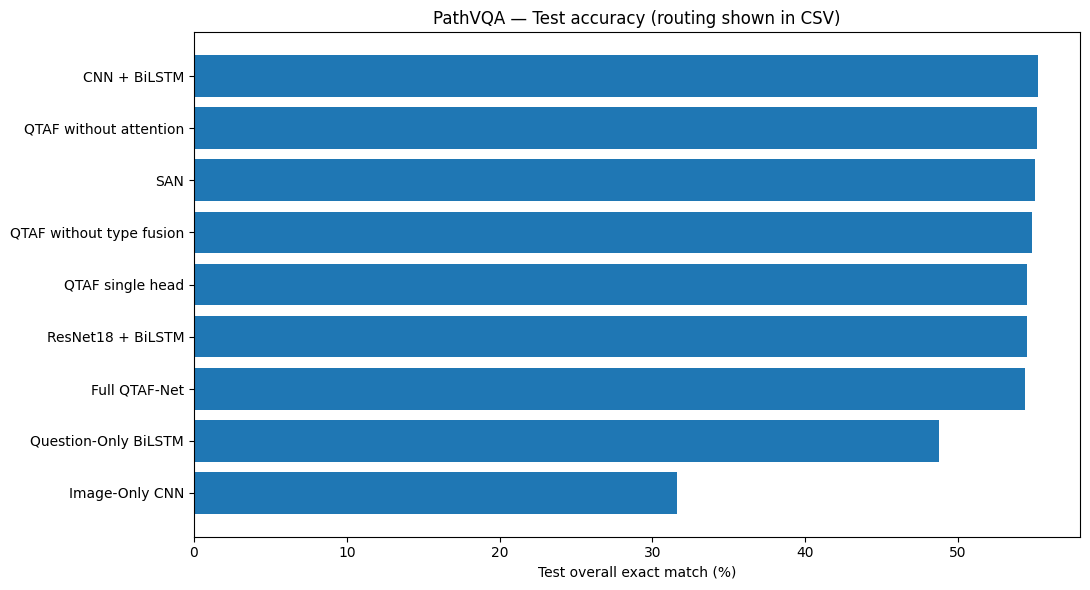

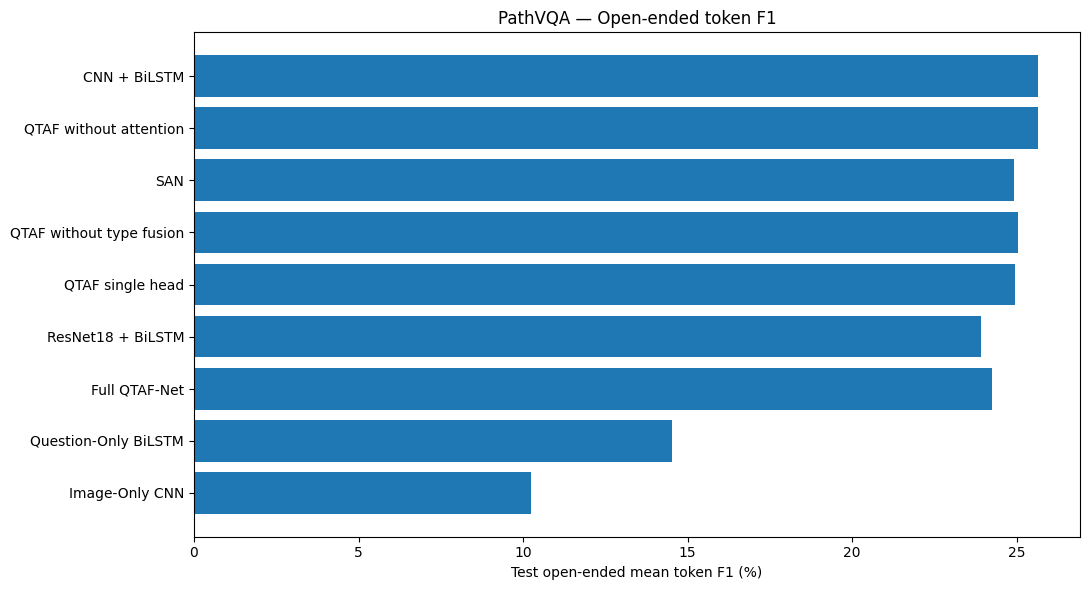

Saved files:
ablation_test_comparison.csv 1.7 KB
all_model_test_metrics.csv 4.2 KB
cnn_bilstm_predictions.csv 652.5 KB
full_qtaf_net_predictions.csv 717.5 KB
image_only_cnn_predictions.csv 653.9 KB
model_test_accuracy.png 71.8 KB
open_token_f1.png 67.4 KB
qtaf_single_head_predictions.csv 820.0 KB
qtaf_without_attention_predictions.csv 778.3 KB
qtaf_without_type_fusion_predictions.csv 793.8 KB
question_only_bilstm_predictions.csv 700.1 KB
resnet18_bilstm_predictions.csv 684.3 KB
san_predictions.csv 593.9 KB


In [20]:
# Plot overall test accuracy across the evaluated model configurations.
main=results[results.routing.isin(['oracle','direct_single_head'])].copy()
main=main.sort_values('overall_exact_match_%')
fig,ax=plt.subplots(figsize=(11,6))
ax.barh(main.model,main['overall_exact_match_%'])
ax.set_xlabel('Test overall exact match (%)')
ax.set_title('PathVQA — Test accuracy (routing shown in CSV)')
fig.tight_layout()
fig.savefig(OUT/'model_test_accuracy.png',dpi=180,bbox_inches='tight')
plt.show()

fig,ax=plt.subplots(figsize=(11,6))
ax.barh(main.model,main['open_token_f1_%'])
ax.set_xlabel('Test open-ended mean token F1 (%)')
ax.set_title('PathVQA — Open-ended token F1')
fig.tight_layout()
fig.savefig(OUT/'open_token_f1.png',dpi=180,bbox_inches='tight')
plt.show()

print('Saved files:')
for f in sorted(OUT.iterdir()): print(f.name, f'{f.stat().st_size/1024:.1f} KB')


## 10. Export the evaluation results

Only CSV predictions, metrics and PNG figures are archived, **not** the large `.pth` files. The test split is used once for final reporting, not for further model selection.

In [21]:
# Bundle evaluation outputs for reproducible reporting.
import zipfile
zip_path=Path('/kaggle/working/pathvqa_final_evaluation_results.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        if f.is_file():z.write(f,arcname=f.name)
print('Created:',zip_path,'Size MB:',round(zip_path.stat().st_size/1024**2,2))


Created: /kaggle/working/pathvqa_final_evaluation_results.zip Size MB: 0.94
